# Mumbai Property Market Analysis
Sale, Rent aur PG listings ka poora analysis: data cleaning, EDA, locality price index, price prediction model, deal detector, rental yield aur dashboard.

## Kaise chalayein
1. Repo ke andar `data/` folder banayein aur CSV file rakhein: `data/8b83c0af-mumbai.csv`
2. `pip install -r requirements.txt`
3. Notebook ko Jupyter, VS Code ya Google Colab mein kholkar **Run all** karein.
4. Saare output charts aur tables `outputs/` folder mein save hote hain.

In [1]:
# ---------- 1. Setup ----------
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
os.makedirs('outputs', exist_ok=True)

CSV_PATH = 'data/8b83c0af-mumbai.csv'
if not os.path.exists(CSV_PATH):
    CSV_PATH = '8b83c0af-mumbai.csv'
print('Using:', CSV_PATH)

Using: data/8b83c0af-mumbai.csv


## 1. Data load aur cleaning
**Interpretation:** Raw file mein 9,514 rows hain, lekin sab use karne layak nahi hain. 246 Sale listings ka price "Price on Request" hai (price = 0), isliye unhe hata diya. 85 aur Sale rows ka ₹/sq ft realistic range se bahar tha, unhe bhi remove kiya. Kul 6,536 clean Sale listings bachi. Ek aur issue: 14 PROP_ID duplicate hain, jo ek hi listing ka double entry ho sakta hai. Ye data quality summary aage ke analysis ko bharosemand banati hai.

In [2]:
df = pd.read_csv(CSV_PATH, low_memory=False)
print('Shape:', df.shape)

df['CITY_NAME'] = df['location'].str.extract(r"'CITY_NAME': '([^']+)'")[0]
df['LOCALITY']  = df['location'].str.extract(r"'LOCALITY_NAME': '([^']+)'")[0]
df['pref']      = df['PREFERENCE'].map({'S': 'Sale', 'R': 'Rent', 'P': 'PG'})
df['BHK']       = df['BEDROOM_NUM']
df['AREA_SQFT'] = df['MIN_AREA_SQFT']
df['post_dt']   = pd.to_datetime(df['POSTING_DATE'], unit='ms', errors='coerce')

# Sale: price > 0 aur ₹/sqft realistic range (1,000 - 3,00,000)
sale = df[(df.pref == 'Sale') & (df.MIN_PRICE > 0) & (df.PRICE_SQFT.between(1000, 300000))].copy()
sale['price_cr'] = sale.MIN_PRICE / 1e7
sale['log_psf']  = np.log(sale.PRICE_SQFT)

rent = df[(df.pref == 'Rent') & (df.MIN_PRICE > 0)].copy()
pg   = df[(df.pref == 'PG') & (df.MIN_PRICE > 0)].copy()

dq = pd.Series({
    'Total rows': len(df),
    'Sale listings (raw)': int((df.pref == 'Sale').sum()),
    'Sale: Price on Request (price = 0), removed': int(((df.pref == 'Sale') & (df.MIN_PRICE == 0)).sum()),
    'Sale: implausible ₹/sqft, removed': int(((df.pref == 'Sale') & (df.MIN_PRICE > 0) & ~df.PRICE_SQFT.between(1000, 300000)).sum()),
    'Sale rows used for analysis': len(sale),
    'Duplicate PROP_ID rows': int(df.PROP_ID.duplicated().sum()),
    'Rent rows used': len(rent),
    'PG rows used': len(pg),
}, name='count')
dq.to_frame()

Shape: (9514, 55)


,count
Total rows,9514
Sale listings (raw),6867
"Sale: Price on Request (price = 0), removed",246
"Sale: implausible ₹/sqft, removed",85
Sale rows used for analysis,6536
Duplicate PROP_ID rows,14
Rent rows used,1244
PG rows used,1403


## 2. Overview aur posting timeline
**Interpretation:** Dataset mein Sale 72% (6,867), PG 15% (1,403) aur Rent 13% (1,244) listings hain. Posting timeline sabse bada pattern dikhati hai: Mar 2023 se listings tez badhti hain, aur **Jul–Aug 2023 mein lagbhag 6,480 listings (68%)** sirf do mahine mein aayi. Ye asli market boom se zyada scraping ya data collection ka effect lagta hai, isliye time-series forecasting is data par abhi reliable nahi hai.

,listings,share_%
pref,,
Sale,6867,72.2
PG,1403,14.7
Rent,1244,13.1


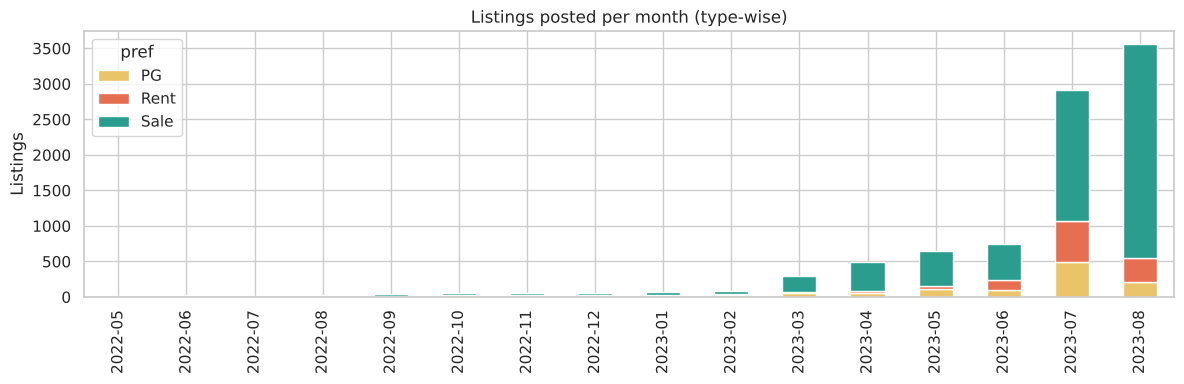

In [3]:
overview = df.pref.value_counts().rename('listings').to_frame()
overview['share_%'] = (overview.listings / overview.listings.sum() * 100).round(1)
display(overview)

monthly = (df.dropna(subset=['post_dt'])
           .groupby([df.post_dt.dt.to_period('M').astype(str), 'pref']).size().unstack(fill_value=0))
ax = monthly.plot(kind='bar', stacked=True, figsize=(12, 4), color=['#e9c46a', '#e76f51', '#2a9d8f'])
ax.set_title('Listings posted per month (type-wise)'); ax.set_xlabel(''); ax.set_ylabel('Listings')
plt.tight_layout(); plt.savefig('outputs/posting_timeline.png', dpi=110); plt.show()

## 3. Sale market: city, BHK aur seller type
**Interpretation:**
- **City:** South Mumbai (~₹51,518/sq ft) aur Mumbai South West (~₹55,000/sq ft) sabse mehenge hain. Navi Mumbai (~₹16,188) aur Mira Road (~₹13,525) mid-to-budget hain, aur Beyond Thane (~₹8,633) sabse sasta. Matlab South Mumbai aur Beyond Thane ke beech ~6 guna ka fark hai.
- **BHK:** Har badhte BHK ke saath total price tezi se badhta hai (1BHK ₹0.70 Cr, 2BHK ₹1.44 Cr, 3BHK ₹2.90 Cr, 4BHK ₹6.00 Cr). Lekin ₹/sq ft 1BHK (₹16,461) se 3BHK (₹27,668) tak hi badhta hai, kyunki bade flats mein per sq ft rate kam hota hai.
- **Seller type:** 87% sale listings **Dealers** post karte hain, owners sirf 9% aur builders 4%. Dealer listings ka median ₹24,305/sq ft hai, owner ka ₹17,018 aur builder ka ₹14,679. Ye observe karna zaroori hai ki dealers ki pricing sabse zyada hai, par ye sirf listing price hai, transaction price nahi.
- **Verified:** sirf 869 listings (13%) verified hain aur unka median ₹16,112/sq ft hai, jabki unverified ka ₹24,423. Ye kyun hai, data se clear nahi hota (ho sakta hai verified mein zyada builder/owner listings hon), isliye iska causal reason mat maaniye.

,listings,median_cr,median_psf
CITY_NAME,,,
Mumbai South West,183,6.80,55000.0
South Mumbai,476,7.10,51518.0
Mumbai Harbour,262,2.75,32293.0
Central Mumbai suburbs,1195,2.00,27947.0
Mumbai Andheri-Dahisar,793,2.11,27169.0
Thane,1069,1.40,20429.0
Navi Mumbai,1830,1.28,16188.0
Mira Road And Beyond,334,0.66,13525.0
Mumbai Beyond Thane,394,0.45,8633.0


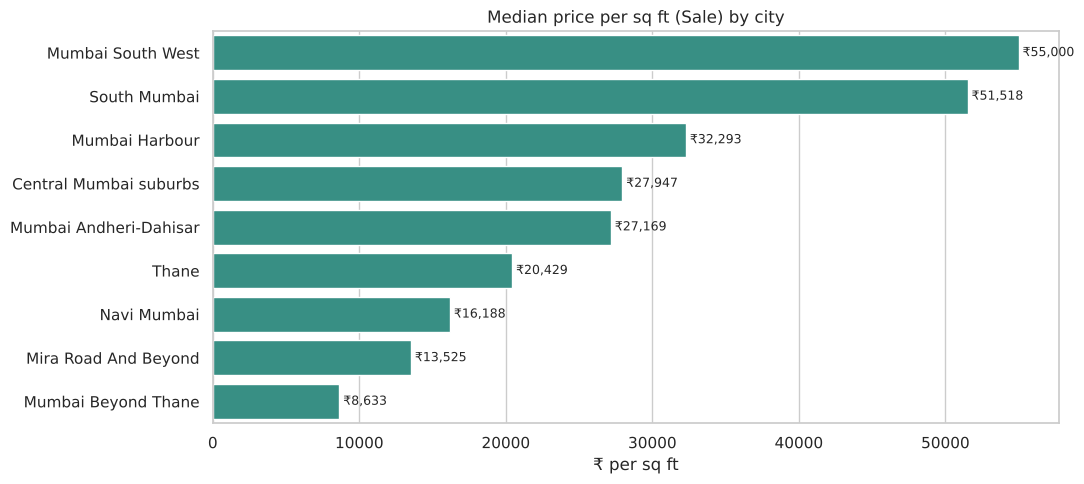

In [4]:
city_tbl = (sale.groupby('CITY_NAME')
            .agg(listings=('SPID', 'size'), median_cr=('price_cr', 'median'), median_psf=('PRICE_SQFT', 'median'))
            .sort_values('median_psf', ascending=False).round(2))
display(city_tbl)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=city_tbl.reset_index(), y='CITY_NAME', x='median_psf', color='#2a9d8f', ax=ax)
for i, v in enumerate(city_tbl.median_psf):
    ax.text(v, i, f' ₹{v:,.0f}', va='center', fontsize=9)
ax.set_title('Median price per sq ft (Sale) by city'); ax.set_xlabel('₹ per sq ft'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig('outputs/city_price_psf.png', dpi=110); plt.show()

,listings,median_cr,median_psf,median_area
BHK,,,,
1.0,1475,0.70,16461.0,39.67
2.0,2598,1.44,21709.0,63.17
3.0,1754,2.90,27667.5,97.64
4.0,579,6.00,33537.0,165.46
5.0,88,11.28,42153.0,251.63


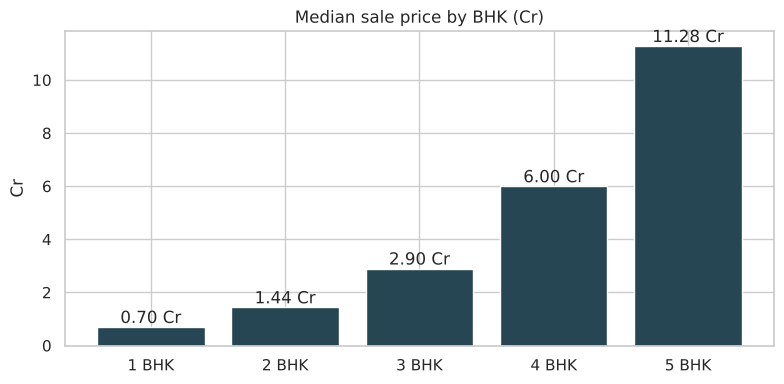

In [5]:
bhk_tbl = (sale[sale.BHK.between(1, 5)].groupby('BHK')
           .agg(listings=('SPID', 'size'), median_cr=('price_cr', 'median'), median_psf=('PRICE_SQFT', 'median'),
                median_area=('MIN_AREA_SQFT', 'median')).round(2))
display(bhk_tbl)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(bhk_tbl.index.astype(int).astype(str) + ' BHK', bhk_tbl.median_cr, color='#264653')
for i, v in enumerate(bhk_tbl.median_cr):
    ax.text(i, v, f'{v:.2f} Cr', ha='center', va='bottom')
ax.set_title('Median sale price by BHK (Cr)'); ax.set_ylabel('Cr')
plt.tight_layout(); plt.savefig('outputs/bhk_price.png', dpi=110); plt.show()

In [6]:
seller = (sale.groupby('CLASS_LABEL')
          .agg(listings=('SPID', 'size'), median_psf=('PRICE_SQFT', 'median'), median_cr=('price_cr', 'median'))
          .round(2))
seller['share_%'] = (seller.listings / seller.listings.sum() * 100).round(1)
display(seller)

verified = sale.groupby('VERIFIED').agg(listings=('SPID', 'size'), median_psf=('PRICE_SQFT', 'median')).round(0)
display(verified)

,listings,median_psf,median_cr,share_%
CLASS_LABEL,,,,
Builder,270,14679.0,0.80,4.1
Dealer,5699,24305.0,1.72,87.2
Owner,567,17018.0,1.00,8.7


,listings,median_psf
VERIFIED,,
N,5667,24423.0
Y,869,16112.0


## 4. Rent aur PG market
**Interpretation:**
- **Rent:** Median rent ₹55,000/month hai. BHK ke hisaab se 1BHK ~₹24,750, 2BHK ₹50,000, 3BHK ₹95,000 aur 4BHK ~₹2,55,000 hai. City-wise South West (~₹1,80,000) aur South Mumbai (~₹1,78,500) sabse mehenge hain, Beyond Thane (~₹10,000) sabse sasta.
- **PG:** Median ₹12,000 per bed hai. South Mumbai mein ₹23,000 aur South West mein ₹18,000 hai, jabki Navi Mumbai (~₹7,000) aur Beyond Thane (~₹5,250) mein kafi sasta hai. Sabse zyada PG listings Andheri-Dahisar (536) mein hain, jo ek busy PG market dikhata hai.

,listings,median_rent
BHK,,
1.0,290,24749.5
2.0,528,50000.0
3.0,324,95000.0
4.0,85,255000.0


,listings,median_rent
CITY_NAME,,
Mumbai South West,71,180000.0
South Mumbai,126,178500.0
Central Mumbai suburbs,281,75000.0
Mumbai Harbour,53,73000.0
Mumbai Andheri-Dahisar,187,62000.0
Navi Mumbai,170,35000.0
Thane,278,32000.0
Mira Road And Beyond,27,18000.0
Mumbai Beyond Thane,51,10000.0


,listings,median_per_bed
CITY_NAME,,
South Mumbai,153,23000.0
Mumbai South West,123,18000.0
Mumbai Harbour,87,13000.0
Central Mumbai suburbs,218,12000.0
Mumbai Andheri-Dahisar,536,11500.0
Thane,115,8000.0
Navi Mumbai,122,6999.5
Mira Road And Beyond,33,5500.0
Mumbai Beyond Thane,16,5250.0


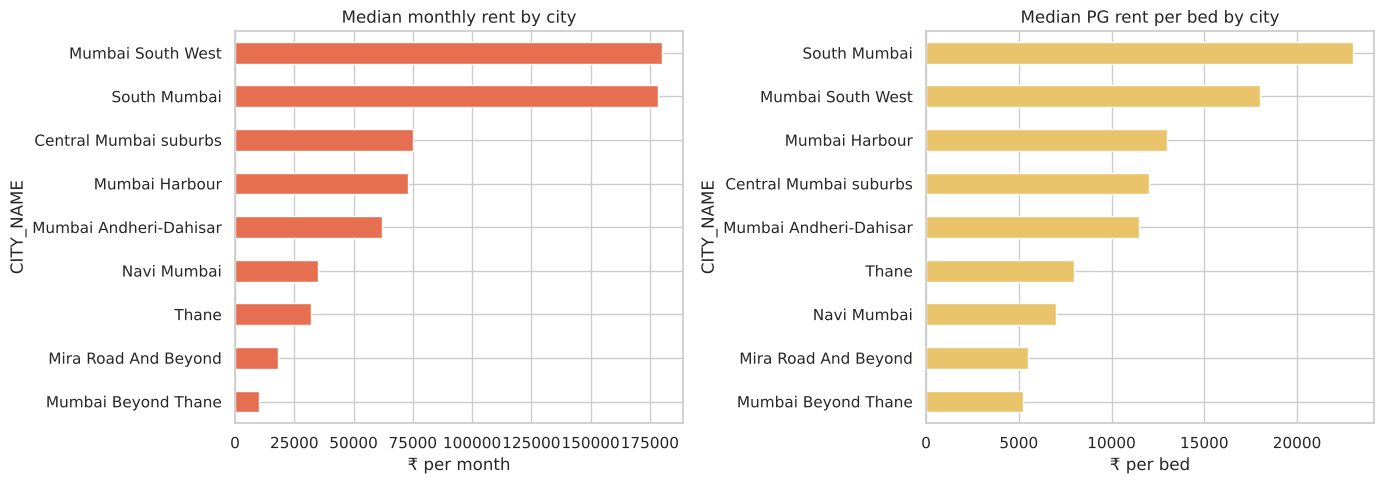

In [7]:
rent_bhk = rent.groupby('BHK').agg(listings=('SPID', 'size'), median_rent=('MIN_PRICE', 'median')).loc[1:4]
rent_city = rent.groupby('CITY_NAME').agg(listings=('SPID', 'size'), median_rent=('MIN_PRICE', 'median')).sort_values('median_rent', ascending=False)
pg_city = pg.groupby('CITY_NAME').agg(listings=('SPID', 'size'), median_per_bed=('MIN_PRICE', 'median')).sort_values('median_per_bed', ascending=False)
display(rent_bhk); display(rent_city); display(pg_city)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rent_city.median_rent.sort_values().plot(kind='barh', ax=axes[0], color='#e76f51')
axes[0].set_title('Median monthly rent by city'); axes[0].set_xlabel('₹ per month')
pg_city.median_per_bed.sort_values().plot(kind='barh', ax=axes[1], color='#e9c46a')
axes[1].set_title('Median PG rent per bed by city'); axes[1].set_xlabel('₹ per bed')
plt.tight_layout(); plt.savefig('outputs/rent_pg_city.png', dpi=110); plt.show()

## 5. Locality price index aur price tiers
**Interpretation:** Localities ko median ₹/sq ft ke quartiles mein 4 tiers mein baanta gaya hai: Budget, Mid, Premium aur Luxury. Top par Bandra West, Khar West, Prabhadevi, Worli, Santacruz West aur Juhu hain (₹57,000 se upar). Bottom par Kalher (~₹5,722), Ambernath, Naigaon East, Kalyan West aur Taloja jaise Thane-belt aur Navi Mumbai ke outer areas hain. Ye index client ko locality compare karne ka simple tool deta hai. Ye ek snapshot hai, isliye kisi locality ka sirf chhota sample size hai to uska number unreliable ho sakta hai (isliye min 15 listings ka filter lagaya gaya).

In [8]:
MIN_LISTINGS = 15
loc = (sale.dropna(subset=['LOCALITY']).groupby(['CITY_NAME', 'LOCALITY'])
       .agg(listings=('SPID', 'size'), median_psf=('PRICE_SQFT', 'median'), median_cr=('price_cr', 'median'))
       .reset_index())
loc = loc[loc.listings >= MIN_LISTINGS].sort_values('median_psf', ascending=False).reset_index(drop=True)
loc['tier'] = pd.qcut(loc.median_psf, 4, labels=['Budget', 'Mid', 'Premium', 'Luxury'])
loc.to_csv('outputs/locality_price_index.csv', index=False)
print('Localities with >=', MIN_LISTINGS, 'listings:', len(loc))
display(loc.head(10)); display(loc.tail(10))

Localities with >= 15 listings: 96


,CITY_NAME,LOCALITY,listings,median_psf,median_cr,tier
0,Mumbai South West,Bandra West,15,76295.0,10.750000,Luxury
1,Mumbai South West,Khar West,16,60000.0,7.305000,Luxury
2,South Mumbai,Prabhadevi,43,59189.0,9.357623,Luxury
3,South Mumbai,Worli,108,58774.0,8.694859,Luxury
4,Mumbai South West,Santacruz West,19,57500.0,5.901741,Luxury
5,Mumbai South West,Juhu,22,57411.0,8.275000,Luxury
6,Mumbai Harbour,Byculla East,25,56716.0,6.890000,Luxury
7,Mumbai South West,Bandra East,27,55000.0,8.055127,Luxury
8,South Mumbai,Mahalaxmi,74,52728.0,7.920000,Luxury
9,South Mumbai,Matunga,40,46995.5,5.163774,Luxury


,CITY_NAME,LOCALITY,listings,median_psf,median_cr,tier
86,Mira Road And Beyond,Virar West,57,9821.0,0.447350,Budget
87,Navi Mumbai,Karanjade,23,9047.0,0.420000,Budget
88,Navi Mumbai,Taloja,51,9042.0,0.410172,Budget
89,Mumbai Beyond Thane,Kalyan West,37,8803.0,0.460000,Budget
90,Mira Road And Beyond,Naigaon East,29,8684.0,0.416973,Budget
91,Mumbai Beyond Thane,Ambernath,28,7478.5,0.350000,Budget
92,Mira Road And Beyond,Vasai West,18,7442.5,0.590000,Budget
93,Navi Mumbai,Kalamboli,15,7164.0,0.720000,Budget
94,Thane,Kalher,23,5722.0,0.222050,Budget
95,Mumbai Beyond Thane,Badlapur West,15,5407.0,0.250000,Budget


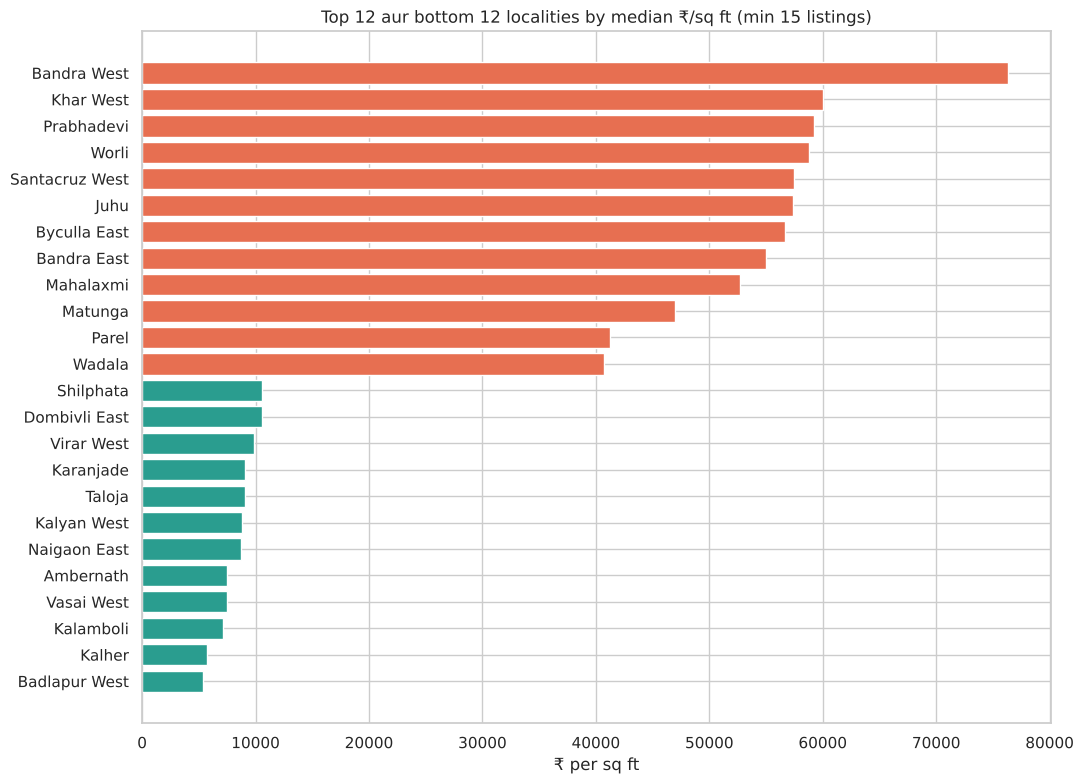

In [9]:
top_bottom = pd.concat([loc.head(12), loc.tail(12)])
top_bottom = top_bottom.sort_values('median_psf')
colors = {'Budget': '#2a9d8f', 'Mid': '#e9c46a', 'Premium': '#f4a261', 'Luxury': '#e76f51'}
fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(top_bottom.LOCALITY, top_bottom.median_psf, color=[colors[t] for t in top_bottom.tier])
ax.set_title('Top 12 aur bottom 12 localities by median ₹/sq ft (min 15 listings)')
ax.set_xlabel('₹ per sq ft')
plt.tight_layout(); plt.savefig('outputs/locality_top_bottom.png', dpi=110); plt.show()

## 6. Price prediction model
Target: `log(PRICE_SQFT)`. Model ko actual listing ke features (city, locality, BHK, area, age, floor, seller type, verified, amenities, landmarks) se fair ₹/sq ft predict karna hai.

**Interpretation:**
- **Random Forest** ka R² 0.756 hai aur MAPE ~19.5%, jabki **Ridge (baseline)** ka R² 0.710 aur MAPE ~23.7% hai. Random Forest behtar hai, lekin dono ka error ~20% ke aaspaas hai. Matlab ye tool estimate ke liye acha hai, par exact price ke liye nahi.
- **Feature importance:** Sabse zyada asar TOTAL_FLOOR (building ki total floors) ka hai, phir city (Beyond Thane, South Mumbai, Navi Mumbai) aur AREA_SQFT ka. Ye correlation hai, causation nahi: floor count ka asar kisi aur factor (jaise project ka level) ki wajah se bhi ho sakta hai.
- **Actual vs predicted** scatter plot mein points red line (perfect prediction) ke aas-paas hone chahiye; chart notebook mein dekh kar check karein.

In [10]:
sale['VERIFIED_FLAG']  = (sale.VERIFIED == 'Y').astype(int)
sale['AMENITY_COUNT']  = sale.AMENITIES.fillna('').str.count(',') + sale.AMENITIES.notna().astype(int)
sale['LANDMARK_COUNT'] = sale.TOTAL_LANDMARK_COUNT.fillna(0)

cat_cols = ['CITY_NAME', 'LOCALITY', 'CLASS_LABEL', 'PROPERTY_TYPE']
num_cols = ['BHK', 'AREA_SQFT', 'AGE', 'TOTAL_FLOOR', 'VERIFIED_FLAG', 'AMENITY_COUNT', 'LANDMARK_COUNT']
fill_vals = {c: 0 for c in num_cols}

X = sale[cat_cols + num_cols]
y = sale['log_psf']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = X_train.fillna(fill_vals); X_test = X_test.fillna(fill_vals)

pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=10), cat_cols),
    ('num', 'passthrough', num_cols),
])

models = {
    'Ridge (baseline)': Pipeline([('pre', pre), ('model', Ridge(alpha=1.0))]),
    'Random Forest': Pipeline([('pre', pre), ('model', RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1))]),
}
results = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred_log = pipe.predict(X_test)
    pred_psf, true_psf = np.exp(pred_log), np.exp(y_test)
    results[name] = {
        'R2 (log scale)': r2_score(y_test, pred_log),
        'MAE (₹/sqft)': mean_absolute_error(true_psf, pred_psf),
        'MAPE (%)': np.mean(np.abs(pred_psf - true_psf) / true_psf) * 100,
    }
metrics = pd.DataFrame(results).T.round(3)
display(metrics)

,R2 (log scale),MAE (₹/sqft),MAPE (%)
Ridge (baseline),0.710,6460.122,23.702
Random Forest,0.756,5481.999,19.517


,importance
TOTAL_FLOOR,0.164
CITY_NAME_Mumbai Beyond Thane,0.137
CITY_NAME_South Mumbai,0.103
CITY_NAME_Navi Mumbai,0.094
AREA_SQFT,0.076
CITY_NAME_Mira Road And Beyond,0.063
CITY_NAME_Thane,0.053
LANDMARK_COUNT,0.039
AMENITY_COUNT,0.036
CITY_NAME_Mumbai South West,0.033


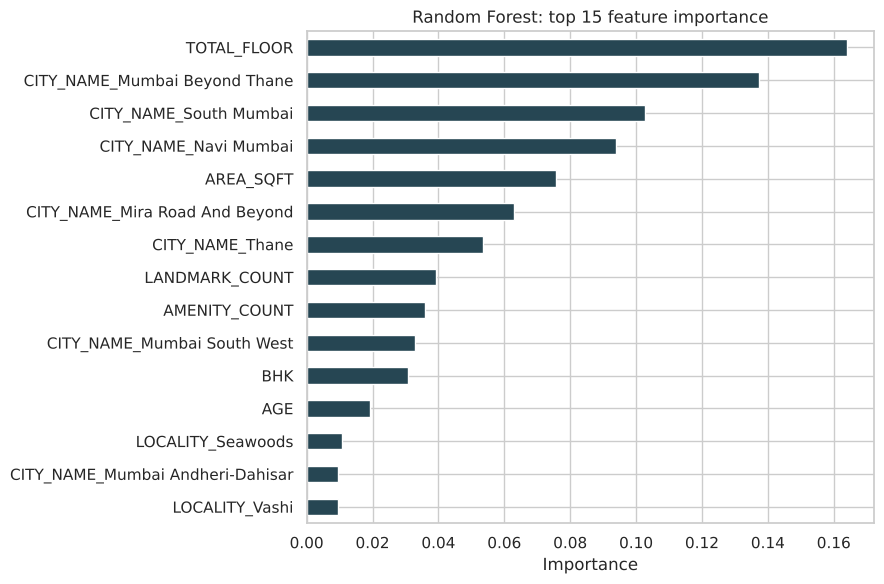

In [11]:
best = models['Random Forest']
names = best.named_steps['pre'].get_feature_names_out()
imp = pd.Series(best.named_steps['model'].feature_importances_, index=names)
imp.index = imp.index.str.replace('cat__', '', regex=False).str.replace('num__', '', regex=False)
imp = imp.sort_values(ascending=False).head(15)
display(imp.round(3).to_frame('importance'))

fig, ax = plt.subplots(figsize=(9, 6))
imp.sort_values().plot(kind='barh', ax=ax, color='#264653')
ax.set_title('Random Forest: top 15 feature importance'); ax.set_xlabel('Importance')
plt.tight_layout(); plt.savefig('outputs/feature_importance.png', dpi=110); plt.show()

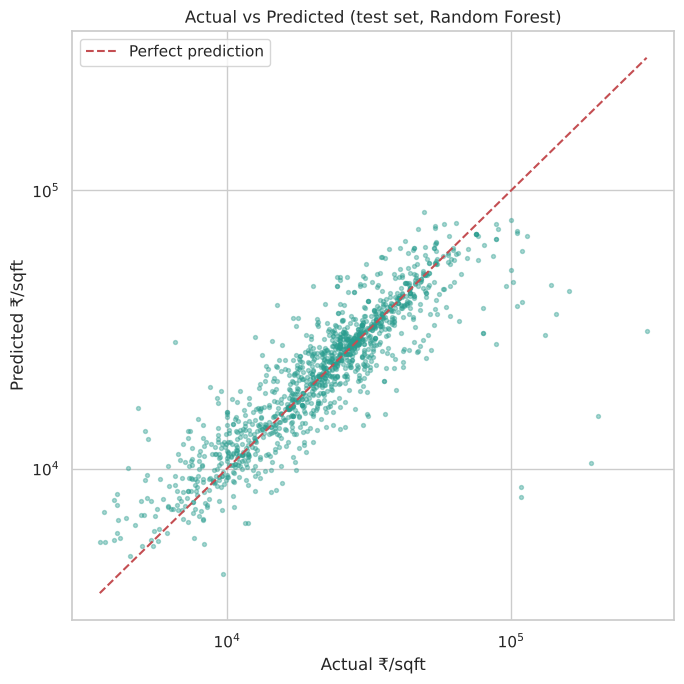

In [12]:
pred_test = np.exp(best.predict(X_test))
true_test = np.exp(y_test)
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(true_test, pred_test, s=8, alpha=0.4, color='#2a9d8f')
lims = [min(true_test.min(), pred_test.min()), max(true_test.max(), pred_test.max())]
ax.plot(lims, lims, 'r--', label='Perfect prediction')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Actual ₹/sqft'); ax.set_ylabel('Predicted ₹/sqft')
ax.set_title('Actual vs Predicted (test set, Random Forest)'); ax.legend()
plt.tight_layout(); plt.savefig('outputs/actual_vs_predicted.png', dpi=110); plt.show()

In [13]:
def estimate_price(city, locality, bhk, area_sqft, age=3, floor=10, class_label='Dealer',
                   prop_type='Residential Apartment', verified=0, amenity_count=10, landmarks=5):
    row = pd.DataFrame([{
        'CITY_NAME': city, 'LOCALITY': locality, 'CLASS_LABEL': class_label, 'PROPERTY_TYPE': prop_type,
        'BHK': bhk, 'AREA_SQFT': area_sqft, 'AGE': age, 'TOTAL_FLOOR': floor,
        'VERIFIED_FLAG': verified, 'AMENITY_COUNT': amenity_count, 'LANDMARK_COUNT': landmarks}])
    psf = float(np.exp(best.predict(row))[0])
    return {'estimated_psf': round(psf), 'estimated_total_cr': round(psf * area_sqft / 1e7, 2)}

print('Example: Thane, Balkum, 2BHK, 650 sq ft ->', estimate_price('Thane', 'Balkum', bhk=2, area_sqft=650))
print('Example: South Mumbai, Worli, 3BHK, 1200 sq ft ->', estimate_price('South Mumbai', 'Worli', bhk=3, area_sqft=1200))

Example: Thane, Balkum, 2BHK, 650 sq ft -> {'estimated_psf': 11894, 'estimated_total_cr': 0.77}
Example: South Mumbai, Worli, 3BHK, 1200 sq ft -> {'estimated_psf': 69954, 'estimated_total_cr': 8.39}


## 7. Overpriced / underpriced listing detector
Fair price cross-validated predictions se nikala gaya. Jo listing ±30% se bahar hai, use flag kiya gaya.

**Interpretation:** 5,085 listings "Fair" hain, **773 "Overpriced"** (fair price se 30% se zyada upar) aur **678 "Underpriced"** (30% se zyada neeche). Ye flags **model ke hisaab se** hain, sach ka proof nahi. Underpriced listings galat data, pehle se hi kam price, ya kisi distress sale ka sign ho sakti hain. Overpriced listings mein dealer ka markup ho sakta hai. Ye list CSV mein `outputs/flagged_listings.csv` par hai, aur negotiation ya manual verification ke liye start point ban sakti hai.

In [14]:
X_all = sale[cat_cols + num_cols].fillna(fill_vals)
detector = Pipeline([('pre', pre), ('model', RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1))])
sale['fair_psf'] = np.exp(cross_val_predict(detector, X_all, sale['log_psf'], cv=5))
sale['deviation_pct'] = (sale.PRICE_SQFT / sale.fair_psf - 1) * 100
sale['deal_flag'] = np.select(
    [sale.deviation_pct > 30, sale.deviation_pct < -30],
    ['Overpriced (>30% upar)', 'Underpriced (>30% neeche)'], default='Fair')

flag_counts = sale.deal_flag.value_counts().rename('listings').to_frame()
display(flag_counts)

flagged = sale[sale.deal_flag != 'Fair'][['SPID', 'CITY_NAME', 'LOCALITY', 'BHK', 'AREA_SQFT', 'CLASS_LABEL',
                                          'PRICE_SQFT', 'fair_psf', 'deviation_pct', 'deal_flag']].round(1)
flagged.sort_values('deviation_pct', ascending=False).to_csv('outputs/flagged_listings.csv', index=False)
print('Top 10 overpriced:'); display(flagged.sort_values('deviation_pct', ascending=False).head(10))
print('Top 10 underpriced:'); display(flagged.sort_values('deviation_pct').head(10))

,listings
deal_flag,
Fair,5085
Overpriced (>30% upar),773
Underpriced (>30% neeche),678


Top 10 overpriced:


,SPID,CITY_NAME,LOCALITY,BHK,AREA_SQFT,CLASS_LABEL,PRICE_SQFT,fair_psf,deviation_pct,deal_flag
8703,69934600,Navi Mumbai,Sector 21 Kharghar,4.0,149.9,Dealer,273333.0,12236.5,2133.7,Overpriced (>30% upar)
1796,64611704,Mumbai Beyond Thane,Dombivli,NaN,229.9,Owner,108695.0,5671.0,1816.7,Overpriced (>30% upar)
1580,69195378,Navi Mumbai,Panvel,1.0,27.1,Owner,191458.0,10203.4,1776.4,Overpriced (>30% upar)
3194,70003104,Mumbai Beyond Thane,Kalyan,3.0,93.9,Owner,151063.0,8146.1,1754.4,Overpriced (>30% upar)
8980,68497000,Mira Road And Beyond,Hatkesh Udhog Nagar,2.0,54.3,Dealer,174600.0,11511.9,1416.7,Overpriced (>30% upar)
5903,70762058,Navi Mumbai,Jui Nagar,1.0,39.5,Dealer,258720.0,19776.6,1208.2,Overpriced (>30% upar)
6339,70217360,Thane,Ghodbunder Road,2.0,59.6,Dealer,203020.0,15525.8,1207.6,Overpriced (>30% upar)
4859,68933520,Navi Mumbai,Taloja,2.0,48.0,Owner,108198.0,9053.1,1095.1,Overpriced (>30% upar)
1369,69875828,Navi Mumbai,Panvel,1.0,42.9,Owner,138956.0,12361.9,1024.1,Overpriced (>30% upar)
2482,69369034,Central Mumbai suburbs,Nahur,3.0,69.5,Dealer,270720.0,24789.2,992.1,Overpriced (>30% upar)


Top 10 underpriced:


,SPID,CITY_NAME,LOCALITY,BHK,AREA_SQFT,CLASS_LABEL,PRICE_SQFT,fair_psf,deviation_pct,deal_flag
1980,65555634,Navi Mumbai,Khalapur Magic Hill Phase 1,4.0,254.9,Owner,2915.0,31395.2,-90.7,Underpriced (>30% neeche)
4666,68974920,Mira Road And Beyond,Virar East,1.0,37.2,Owner,1125.0,11881.2,-90.5,Underpriced (>30% neeche)
8610,70253564,Mira Road And Beyond,Virar West,2.0,374.5,Dealer,1265.0,10247.5,-87.7,Underpriced (>30% neeche)
4772,69996730,Central Mumbai suburbs,Hiranandani Gardens Powai,2.0,647.3,Dealer,5109.0,34815.9,-85.3,Underpriced (>30% neeche)
1536,54630286,Mumbai Beyond Thane,Atgaon,NaN,195.0,Owner,1048.0,5468.8,-80.8,Underpriced (>30% neeche)
887,69933536,Mumbai Beyond Thane,Vangani,2.0,87.3,Builder,2234.0,10282.6,-78.3,Underpriced (>30% neeche)
7983,69861108,South Mumbai,Curry Road East,1.0,55.7,Dealer,12500.0,54199.3,-76.9,Underpriced (>30% neeche)
1318,22476231,Navi Mumbai,Kharghar,8.0,278.7,Owner,6334.0,26849.4,-76.4,Underpriced (>30% neeche)
4252,71012754,Navi Mumbai,Koperkhairane,3.0,159.3,Dealer,4177.0,17046.8,-75.5,Underpriced (>30% neeche)
3733,70570052,Navi Mumbai,Nerul,3.0,565.0,Dealer,6576.0,25871.0,-74.6,Underpriced (>30% neeche)


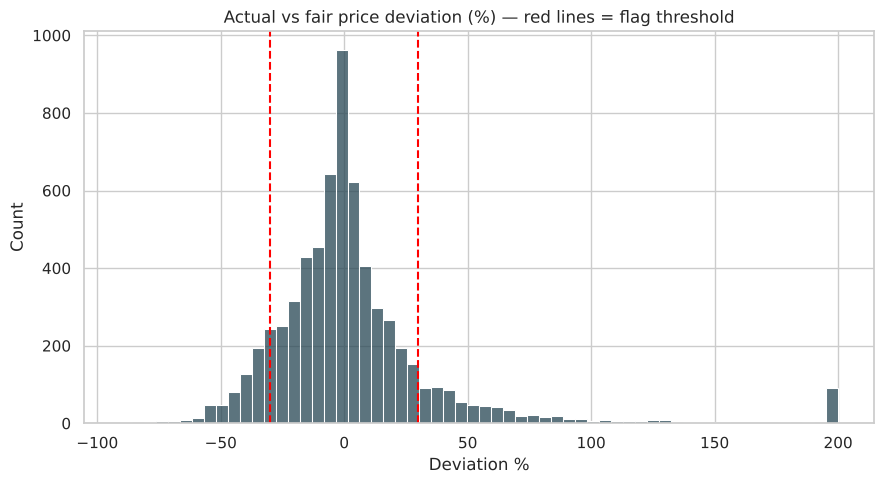

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(sale.deviation_pct.clip(-100, 200), bins=60, ax=ax, color='#264653')
ax.axvline(30, color='red', ls='--'); ax.axvline(-30, color='red', ls='--')
ax.set_title('Actual vs fair price deviation (%) — red lines = flag threshold')
ax.set_xlabel('Deviation %')
plt.tight_layout(); plt.savefig('outputs/deviation_hist.png', dpi=110); plt.show()

## 8. Rental yield (2BHK, locality-wise)
**Interpretation:** Sirf 27 localities mein itna data hai ki sale aur rent dono compare ho sake. **Vikhroli East** (~7.5%) sabse upar hai, phir Goregaon East (~5.1%) aur Marol (~4.5%). Bottom par Dombivli East (~1.9%) aur Kharghar (~2.7%) hain. Ek achha investor rule: 4% se upar gross yield ko accha maana jata hai, par ye chhota sample hai aur maintenance, vacancy aur tax is number mein shamil nahi hain, isliye ise net return na samjhein.

Localities with enough data: 27


,sale_cr,sale_n,rent_pm,rent_n,gross_yield_pct
LOCALITY,,,,,
Vikhroli East,1.27,17,80000.0,6,7.54
Goregaon East,1.75,25,74000.0,8,5.07
Marol,1.87,26,70000.0,12,4.49
Chandivali,1.85,32,68000.0,8,4.41
Wadala East,2.40,11,87500.0,8,4.38
Chembur,1.97,18,70000.0,8,4.26
Chembur East,1.98,14,70000.0,5,4.24
Kanjurmarg west,1.59,18,55000.0,8,4.15
Malad West,1.71,19,58500.0,6,4.11


,sale_cr,sale_n,rent_pm,rent_n,gross_yield_pct
LOCALITY,,,,,
Seawoods,2.25,31,55000.0,5,2.93
Ghodbunder Road,0.91,18,22000.0,12,2.90
Anand Nagar,0.94,7,21750.0,6,2.78
Kharghar,1.26,118,28000.0,7,2.67
Dombivli East,0.63,55,10000.0,11,1.90


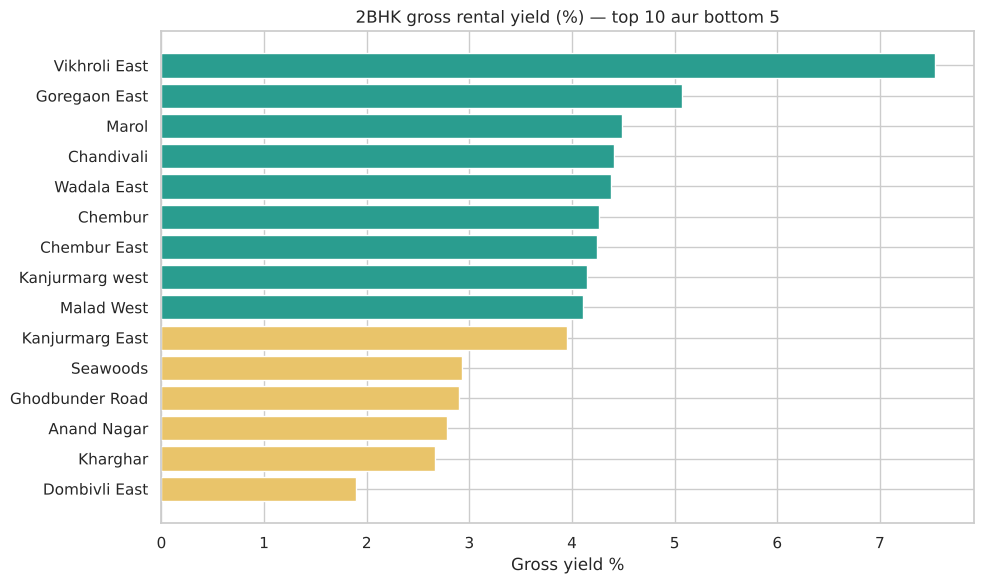

In [16]:
s2 = sale[sale.BHK == 2].groupby('LOCALITY').agg(sale_cr=('price_cr', 'median'), sale_n=('SPID', 'size'))
r2 = rent[rent.BHK == 2].groupby('LOCALITY').agg(rent_pm=('MIN_PRICE', 'median'), rent_n=('SPID', 'size'))
yld = s2.join(r2, how='inner')
yld = yld[(yld.sale_n >= 5) & (yld.rent_n >= 5)].copy()
yld['gross_yield_pct'] = (yld.rent_pm * 12 / (yld.sale_cr * 1e7)) * 100
yld = yld.sort_values('gross_yield_pct', ascending=False).round(2)
yld.to_csv('outputs/rental_yield_2bhk.csv')
print('Localities with enough data:', len(yld))
display(yld.head(10)); display(yld.tail(5))

plot_df = pd.concat([yld.head(10), yld.tail(5)]).sort_values('gross_yield_pct')
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(plot_df.index, plot_df.gross_yield_pct, color=np.where(plot_df.gross_yield_pct >= 4, '#2a9d8f', '#e9c46a'))
ax.set_title('2BHK gross rental yield (%) — top 10 aur bottom 5'); ax.set_xlabel('Gross yield %')
plt.tight_layout(); plt.savefig('outputs/rental_yield.png', dpi=110); plt.show()

## 9. Dashboard
Ek jagah sab key numbers. Ye image `outputs/dashboard.png` mein bhi save hota hai.

**Ek nazar mein:** Median sale ₹/sq ft ₹23,420 hai, median rent ₹55,000/month, median PG ₹12,000/bed hai, aur 87% sale listings dealers ki hain. Price ka sabse bada factor city hai, aur sabse mehenge localities South Mumbai aur South West mein hain.

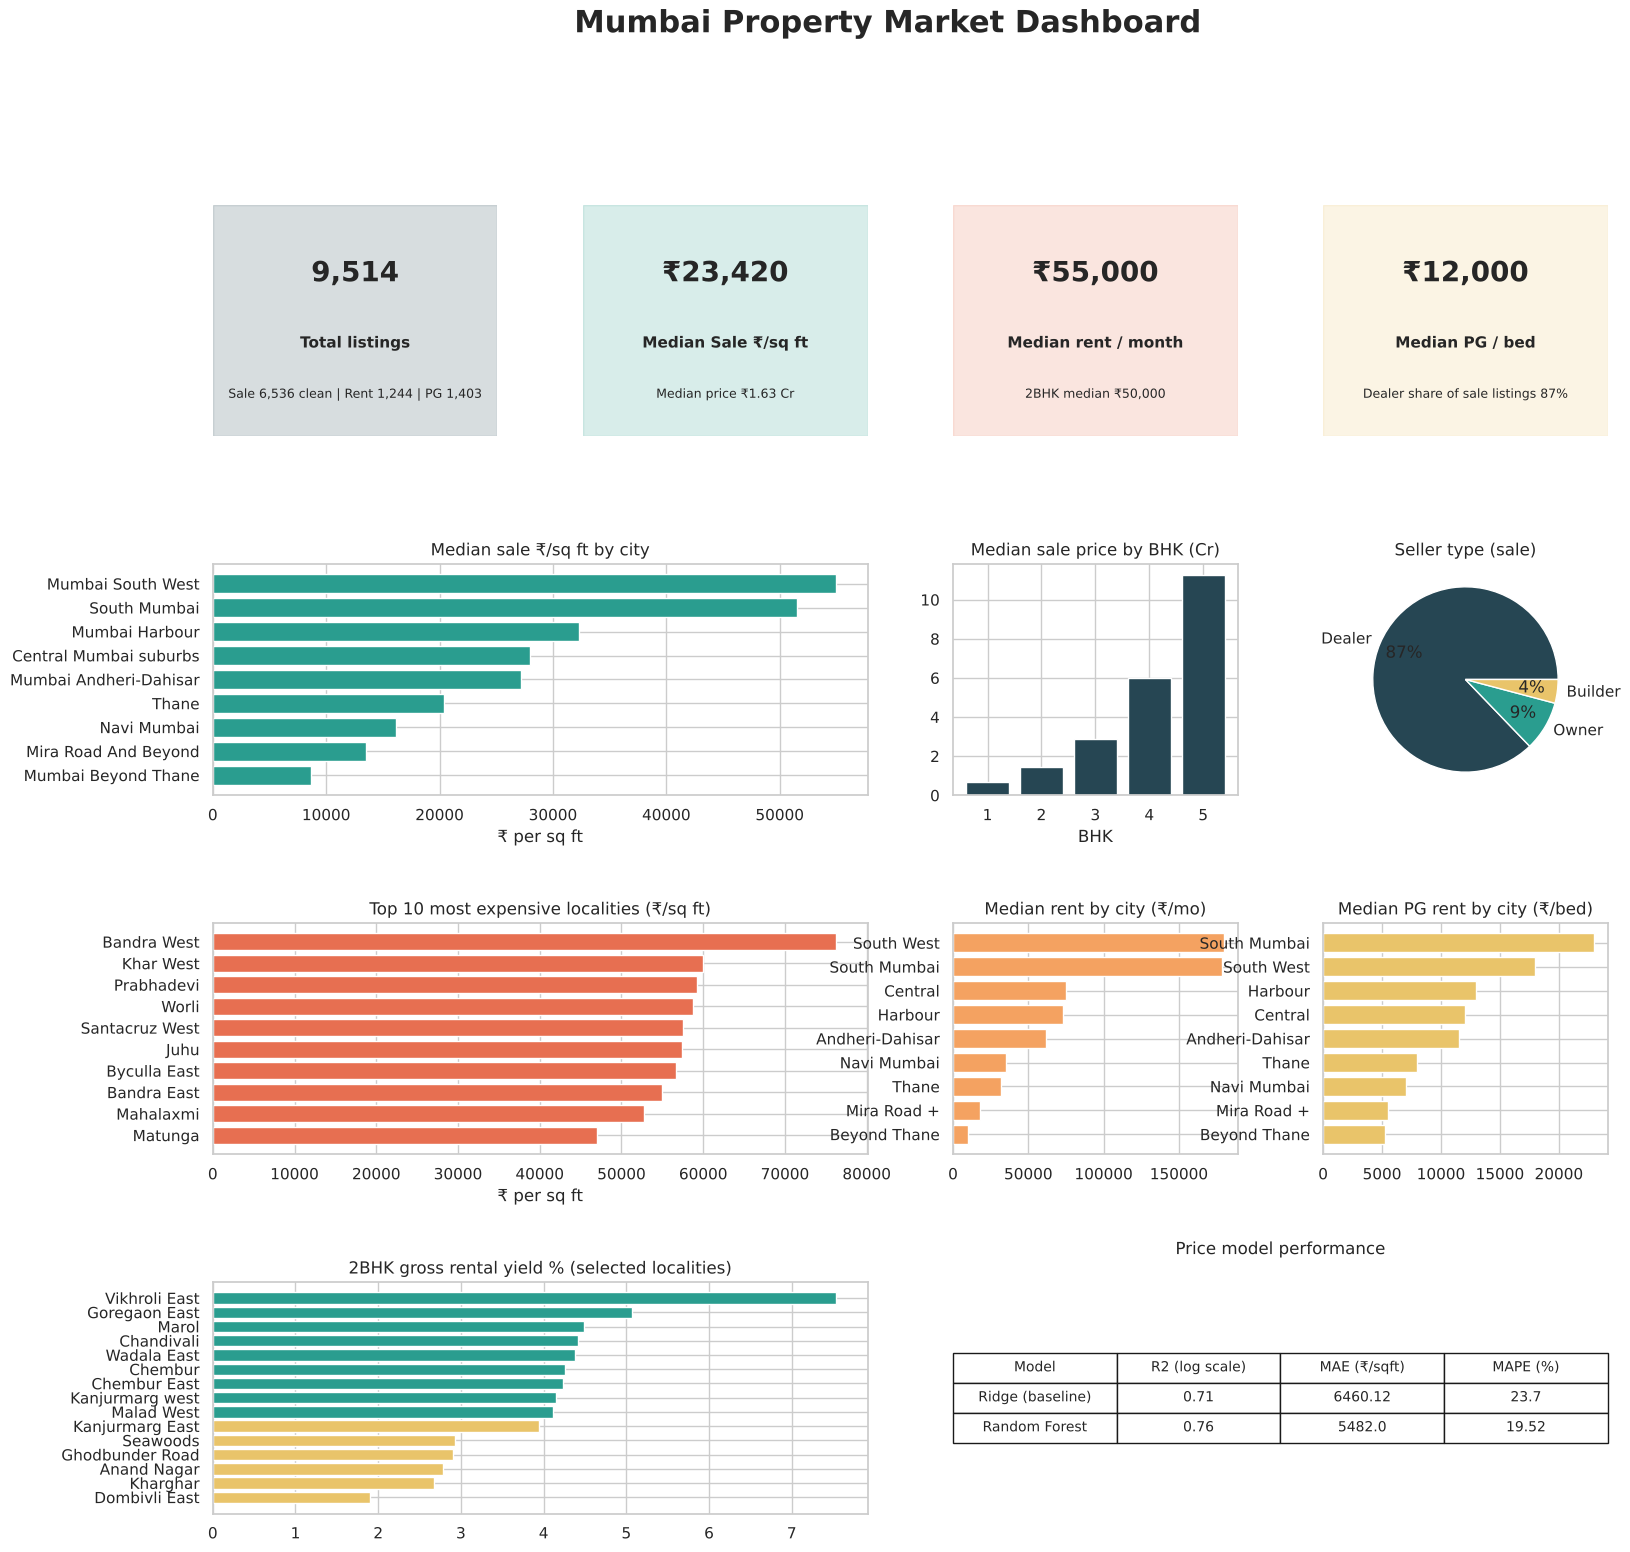

In [17]:
fig = plt.figure(figsize=(18, 17))
gs = fig.add_gridspec(4, 4, hspace=0.55, wspace=0.3)

def kpi(ax, title, value, sub, color):
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color=color, alpha=0.18))
    ax.text(0.5, 0.70, value, ha='center', va='center', fontsize=20, weight='bold', transform=ax.transAxes)
    ax.text(0.5, 0.40, title, ha='center', va='center', fontsize=11, weight='bold', transform=ax.transAxes)
    ax.text(0.5, 0.18, sub, ha='center', va='center', fontsize=9, transform=ax.transAxes)

dealer_share = seller.loc['Dealer', 'share_%'] if 'Dealer' in seller.index else np.nan
kpi(fig.add_subplot(gs[0, 0]), 'Total listings', f'{len(df):,}', f'Sale {len(sale):,} clean | Rent {len(rent):,} | PG {len(pg):,}', '#264653')
kpi(fig.add_subplot(gs[0, 1]), 'Median Sale ₹/sq ft', f'₹{sale.PRICE_SQFT.median():,.0f}', f'Median price ₹{sale.price_cr.median():.2f} Cr', '#2a9d8f')
kpi(fig.add_subplot(gs[0, 2]), 'Median rent / month', f'₹{rent.MIN_PRICE.median():,.0f}', f'2BHK median ₹{rent[rent.BHK==2].MIN_PRICE.median():,.0f}', '#e76f51')
kpi(fig.add_subplot(gs[0, 3]), 'Median PG / bed', f'₹{pg.MIN_PRICE.median():,.0f}', f'Dealer share of sale listings {dealer_share:.0f}%', '#e9c46a')

ax = fig.add_subplot(gs[1, 0:2])
cp = city_tbl.sort_values('median_psf')
ax.barh(cp.index, cp.median_psf, color='#2a9d8f')
ax.set_title('Median sale ₹/sq ft by city'); ax.set_xlabel('₹ per sq ft')

ax = fig.add_subplot(gs[1, 2])
ax.bar(bhk_tbl.index.astype(int).astype(str), bhk_tbl.median_cr, color='#264653')
ax.set_title('Median sale price by BHK (Cr)'); ax.set_xlabel('BHK')

ax = fig.add_subplot(gs[1, 3])
seller_counts = sale.CLASS_LABEL.value_counts()
ax.pie(seller_counts, labels=seller_counts.index, autopct='%1.0f%%', pctdistance=0.72, colors=['#264653', '#2a9d8f', '#e9c46a'])
ax.set_title('Seller type (sale)')

ax = fig.add_subplot(gs[2, 0:2])
tb = loc.head(10).sort_values('median_psf')
ax.barh(tb.LOCALITY, tb.median_psf, color='#e76f51')
ax.set_title('Top 10 most expensive localities (₹/sq ft)'); ax.set_xlabel('₹ per sq ft')

ax = fig.add_subplot(gs[2, 2])
short = lambda s: s.replace('Mumbai ', '').replace(' And Beyond', ' +').replace('Central suburbs', 'Central')
rc = rent_city.median_rent.sort_values()
ax.barh(rc.index.map(short), rc.values, color='#f4a261')
ax.set_title('Median rent by city (₹/mo)')

ax = fig.add_subplot(gs[2, 3])
pc = pg_city.median_per_bed.sort_values()
ax.barh(pc.index.map(short), pc.values, color='#e9c46a')
ax.set_title('Median PG rent by city (₹/bed)')

ax = fig.add_subplot(gs[3, 0:2])
ax.barh(plot_df.index, plot_df.gross_yield_pct, color=np.where(plot_df.gross_yield_pct >= 4, '#2a9d8f', '#e9c46a'))
ax.set_title('2BHK gross rental yield % (selected localities)')

ax = fig.add_subplot(gs[3, 2:4])
ax.axis('off')
tbl_text = metrics.reset_index().rename(columns={'index': 'Model'})
tbl = ax.table(cellText=tbl_text.round(2).values, colLabels=tbl_text.columns, loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1, 1.8)
ax.set_title('Price model performance', pad=20)

fig.suptitle('Mumbai Property Market Dashboard', fontsize=22, weight='bold', y=0.995)
fig.savefig('outputs/dashboard.png', dpi=110, bbox_inches='tight')
plt.show()

## 10. Excel report export
Sab tables ek Excel file mein hain (`outputs/mumbai_property_report.xlsx`), har analysis ke liye alag sheet ke saath. Client ko bhejne ya aage analysis karne ke liye useful hai.

In [18]:
with pd.ExcelWriter('outputs/mumbai_property_report.xlsx', engine='openpyxl') as w:
    overview.to_excel(w, sheet_name='Overview')
    dq.to_frame().to_excel(w, sheet_name='Data_Quality')
    city_tbl.to_excel(w, sheet_name='City_Summary')
    bhk_tbl.to_excel(w, sheet_name='BHK_Summary')
    seller.to_excel(w, sheet_name='Seller_Type')
    rent_city.to_excel(w, sheet_name='Rent_by_City')
    pg_city.to_excel(w, sheet_name='PG_by_City')
    loc.to_excel(w, sheet_name='Locality_Index', index=False)
    metrics.to_excel(w, sheet_name='Model_Metrics')
    flagged.sort_values('deviation_pct', ascending=False).to_excel(w, sheet_name='Deal_Flags', index=False)
    yld.to_excel(w, sheet_name='Rental_Yield_2BHK')
print('Saved outputs/mumbai_property_report.xlsx')

Saved outputs/mumbai_property_report.xlsx


## 11. Key insights aur limitations

### Mukhya nateeje
1. **Mumbai ka price gradient bahut bada hai:** South Mumbai/South West ~₹51,000–55,000/sq ft, jabki Beyond Thane ~₹8,600/sq ft. Location sabse bada factor hai.
2. **Dealers market par haavi hain:** 87% sale listings dealers ki hain, to listing prices ko transaction price ki tarah padhna sahi nahi hoga.
3. **Rent aur PG ka alag market:** PG mein Andheri-Dahisar sabse busy hai, aur rent mein South Mumbai/South West sabse mehenge hain.
4. **Model acha lekin approximate hai:** ~19.5% MAPE ka matlab estimate ka error ~20% tak ho sakta hai.
5. **Kuch localities investor ke liye interesting:** Vikhroli East aur Goregaon East (2BHK) mein gross yield 5% se upar hai.

### Limitations
- **Purana data:** listings May 2022 se Aug 2023 tak ki hain. Aaj ki market ke liye fresh data chahiye.
- **Posting spike:** Jul–Aug 2023 mein 68% data hai, to ye ek snapshot ho sakta hai, poora market nahi.
- **Asking vs transaction price:** ye listing prices hain, actual deal price nahi.
- **Unknown codes:** FURNISH aur FACING numeric codes ka legend file mein nahi hai, isliye unhe model mein use nahi kiya gaya.
- **Correlation, causation nahi:** feature importance ye batata hai ki model kin features ko use karta hai, ye nahi ki wo price ka cause hain.

### Next steps
- Latest listings data (2025–2026) lekar notebook dobara run karna.
- FURNISH aur FACING ka legend mil jaye to model mein unhe add karna.
- Lat-long data (agar MAP_DETAILS mein ho) se map-based heatmap banana.
- Streamlit app banakar `estimate_price()` function ko live tool mein badalna.